## Imports

In [58]:
import gymnasium as gym
from gymnasium import spaces

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.autograd import grad

import numpy as np

import matplotlib.pyplot as plt

## HYPERPARAMETERS

In [59]:
# Durée d’entraînement
dt = 0.1
ROLLOUT_LEN = 256
EPISODES = 5000

# Discount & GAE
r_cont = 0.05
GAMMA = 1/(1 + 0.05*dt)
GAE_LAMBDA = 0.95

# PPO
CLIP_EPS = 0.2
UPDATE_EPOCHS = 4
MINIBATCH_SIZE = 1024
MAX_GRAD_NORM = 0.5

# HJB
LAMBDA_HJB = 0.1

# Optimisation
ACTOR_LR = 3e-4
CRITIC_LR = 1e-3

MAX_STEPS = 200

ENTROPY_COEF = 0.01
VALUE_COEF = 0.5

## Environnement


In [60]:
class PetroleumEnv(gym.Env):
    metadata = {"render.modes": ["human"]}

    def __init__(
        self,
        x0: float = 1.0,
        dt: float = dt,
        r_continuous: float = 1.0,
        tol: float = 1e-3,
        max_steps: int = MAX_STEPS,
    ):
        super().__init__()
        self.x0 = x0
        self.dt = dt
        self.r_cont = r_continuous
        self.gamma = 1.0 / (1.0 + self.r_cont * self.dt)
        self.tol, self.max_steps = tol, max_steps

        self.observation_space = spaces.Box(
            low=np.array([0.0], dtype=np.float32),
            high=np.array([self.x0], dtype=np.float32),
            dtype=np.float32,
        )
        self.action_space = spaces.Box(
            low=np.array([0.0], dtype=np.float32),
            high=np.array([1.0], dtype=np.float32),
            dtype=np.float32,
        )
        self.reset()

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.x = self.x0
        self.step_count = 0
        return np.array([self.x], dtype=np.float32), {}

    def step(self, action):
        # expect action as array-like of shape (1,)
        q = float(np.clip(action, 0.0, 1.0)[0])
        self.x = max(self.x - q * self.dt, 0.0)
        reward = (1.0 - q) * q * self.dt
        self.step_count += 1

        terminated = bool(self.x < self.tol)
        truncated = bool(self.step_count >= self.max_steps)

        obs = np.array([self.x], dtype=np.float32)
        info = {"discount_factor": self.gamma, "step": self.step_count}
        return obs, reward, terminated, truncated, info

    def render(self, mode="human"):
        print(f"Step {self.step_count:4d}  Stock = {self.x:.6f}")

## Actor and Critic


In [61]:
class Actor(nn.Module):
    def __init__(self, obs_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, 2),
        )
        self.softplus = nn.Softplus()

    def forward(self, x):
        alpha, beta = self.net(x).unbind(-1)
        alpha = self.softplus(alpha) + 1e-4
        beta = self.softplus(beta) + 1e-4
        return torch.distributions.Beta(alpha, beta)

class Critic(nn.Module):
    def __init__(self, obs_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 64),
            nn.ReLU(),               # <- ici
            nn.Linear(64, 64),
            nn.ReLU(),               # <- et ici
            nn.Linear(64, 1),
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)

## Buffer

In [62]:
class RolloutBuffer:
    def __init__(self, size, obs_dim):
        self.obs      = torch.zeros(size+1, obs_dim)
        self.actions  = torch.zeros(size)
        self.logprobs = torch.zeros(size)
        self.rewards  = torch.zeros(size)
        self.dones    = torch.zeros(size)
        self.values   = torch.zeros(size+1)
        self.ptr      = 0
        self.max_size = size

    def add(self, obs, action, logp, reward, done, value):
        i = self.ptr
        self.obs[i]      = torch.as_tensor(obs)
        self.actions[i]  = action
        self.logprobs[i] = logp
        self.rewards[i]  = reward
        self.dones[i]    = done
        self.values[i]   = value
        self.ptr += 1

    def bootstrap(self, last_value, last_obs):
        self.values[self.ptr] = last_value
        self.obs[self.ptr]    = torch.as_tensor(last_obs)

    def reset(self):
        self.ptr = 0

In [63]:
def compute_gae(rewards, dones, values, gamma, lam):
    T = len(rewards)
    adv = torch.zeros(T)
    gae = 0.0
    for t in reversed(range(T)):
        δ = rewards[t] + gamma * values[t+1] * (1 - dones[t]) - values[t]
        gae = δ + gamma * lam * (1 - dones[t]) * gae
        adv[t] = gae
    returns = adv + values[:-1]
    return adv, returns

def compute_hjb_batch_loss(states, next_states, rewards, critic, gamma, dt):
    # on veut R_density = rewards / dt
    R_density = rewards.detach() / dt

    states      = states.detach().requires_grad_(True)
    next_states = next_states.detach()
    # prédiction V(x_t)
    v_pred      = critic(states).squeeze(-1)
    # ∇_x V(x_t)
    grads       = grad(v_pred.sum(), states, retain_graph=True)[0].squeeze(-1)
    # f(x_t) ≈ (x_{t+1}-x_t) / dt
    f_approx    = (next_states.squeeze(-1) - states.squeeze(-1)) / dt
    # résidu HJB corrigé
    resid       = v_pred * torch.log(torch.tensor(gamma)) + R_density + grads * f_approx

    return (resid**2).mean()


def ppo_clip_loss(dist, actions, old_logp, advantages, clip_eps):
    new_logp = dist.log_prob(actions)
    ratio    = torch.exp(new_logp - old_logp)
    unclipped = ratio * advantages
    clipped   = torch.clamp(ratio, 1-clip_eps, 1+clip_eps) * advantages
    actor_loss = -torch.min(unclipped, clipped).mean()
    entropy    = dist.entropy().mean()
    return actor_loss, entropy

## Agent

In [64]:
env = env = PetroleumEnv(r_continuous=r_cont, dt=dt)

class HJBPPOAgent:
    def __init__(self, obs_dim):
        # modèles
        self.actor  = Actor(obs_dim)
        self.critic = Critic(obs_dim)
        # opti
        self.actor_opt  = optim.Adam(self.actor.parameters(),  lr=ACTOR_LR)
        self.critic_opt = optim.Adam(self.critic.parameters(), lr=CRITIC_LR)
        # buffer
        self.buffer = RolloutBuffer(ROLLOUT_LEN, obs_dim)

    def select_action(self, obs, noise=True):
        """
        Si noise=True, échantillonne.
        Sinon, retourne la moyenne de la Beta (action déterministe).
        """
        obs_t = torch.as_tensor(obs, dtype=torch.float32)
        dist  = self.actor(obs_t)
        value = self.critic(obs_t).item()
        if noise:
            a_t    = dist.sample()
            logp   = dist.log_prob(a_t).item()
            action = a_t.item()
        else:
            # Beta.mean = α/(α+β)
            action = dist.mean.item()
            logp   = dist.log_prob(torch.as_tensor(action)).item()
        return action, logp, value

    def store_transition(self, obs, action, logp, reward, done, value):
        self.buffer.add(obs, action, logp, reward, done, value)

    def update(self, env):
        # 1) Bootstrap de la dernière valeur
        with torch.no_grad():
            last_value = self.critic(torch.as_tensor(env_last_obs, dtype=torch.float32)).item()
        self.buffer.bootstrap(last_value, env_last_obs)

        # ===> À la place de compute_gae, on calcule manuellement les retours <===
        rewards = self.buffer.rewards         # shape [T]
        dones   = self.buffer.dones           # shape [T]
        values  = self.buffer.values          # shape [T+1]

        # initialisation
        returns = torch.zeros_like(rewards)
        acc     = last_value
        # backward pass
        for t in reversed(range(len(rewards))):
            # si done[t]==1 on ne propage pas la valeur d’après
            acc = rewards[t] + GAMMA * acc * (1 - dones[t])
            returns[t] = acc

        # et si vous avez toujours besoin d’advantages "classiques" :
        advantages = returns - values[:-1]

        # normalisation (optionnelle, mais recommandée)
        advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

        # 2) PPO-epochs exactly comme avant, en utilisant `returns` et `advantages` :
        obs      = self.buffer.obs[:-1]
        actions  = self.buffer.actions
        old_logp = self.buffer.logprobs

        for _ in range(UPDATE_EPOCHS):
            idx = torch.randperm(ROLLOUT_LEN)
            for start in range(0, ROLLOUT_LEN, MINIBATCH_SIZE):
                mb = idx[start:start+MINIBATCH_SIZE]

                # actor loss (idem)
                dist        = self.actor(obs[mb])
                a_loss, ent = ppo_clip_loss(dist, actions[mb], old_logp[mb], advantages[mb], CLIP_EPS)

                # critic MSE avec nos returns
                v_pred      = self.critic(obs[mb]).squeeze(-1)
                mse_u       = (returns[mb] - v_pred).pow(2).mean()

                # HJB loss (idem)
                nb_states   = obs[mb]
                nb_next     = self.buffer.obs[mb+1]
                nb_rewards  = self.buffer.rewards[mb]
                hjb_loss    = compute_hjb_batch_loss(
                                  nb_states, nb_next, nb_rewards,
                                  self.critic, GAMMA, env.dt
                              )

                critic_loss = 0.5*mse_u + LAMBDA_HJB * hjb_loss
                total_loss  = a_loss + VALUE_COEF*critic_loss - ENTROPY_COEF*ent

                # backward + step
                self.actor_opt.zero_grad()
                self.critic_opt.zero_grad()
                total_loss.backward()
                nn.utils.clip_grad_norm_(self.actor.parameters(),  MAX_GRAD_NORM)
                nn.utils.clip_grad_norm_(self.critic.parameters(), MAX_GRAD_NORM)
                self.actor_opt.step()
                self.critic_opt.step()

        # 3) reset buffer
        self.buffer.reset()

    def save(self, path):
        torch.save({
            'actor':  self.actor.state_dict(),
            'critic': self.critic.state_dict(),
        }, path)

    def load(self, path):
        ckpt = torch.load(path)
        self.actor.load_state_dict(ckpt['actor'])
        self.critic.load_state_dict(ckpt['critic'])

## Train the agent


In [65]:
agent = HJBPPOAgent(obs_dim=1)

episode_idx       = 0
reward_history    = []
obs, _            = env.reset()

# nouveaux compteurs pour le discounted return
episode_discounted = 0.0
step_count         = 0


obs, _ = env.reset()
while episode_idx < EPISODES:
    action, logp, value = agent.select_action(obs, noise=True)
    next_obs, reward, done, trunc, info = env.step(np.array([action], dtype=np.float32))

    # stockage classique
    agent.store_transition(obs, action, logp, reward, done or trunc, value)
    obs = next_obs

    # 1. on cumule un discounted return
    episode_discounted += (GAMMA**step_count) * reward
    step_count += 1

    # 2. update PPO dès que le buffer est plein, AVANT tout reset !
    if agent.buffer.ptr >= ROLLOUT_LEN:
        env_last_obs = obs               # dernier état réel
        agent.update(env)

    # 3. quand l’épisode se termine…
    if done or trunc:
        episode_idx += 1
        reward_history.append(episode_discounted)
        print(f"episode {episode_idx:>4} | Reward: {episode_discounted:.3f}")

        # réinitialisation des compteurs
        episode_discounted = 0.0
        step_count         = 0

        # reset de l’env
        obs, _ = env.reset()

episode    1 | Reward: 0.167
episode    2 | Reward: 0.267
episode    3 | Reward: 0.239
episode    4 | Reward: 0.316
episode    5 | Reward: 0.348
episode    6 | Reward: 0.368
episode    7 | Reward: 0.269
episode    8 | Reward: 0.271
episode    9 | Reward: 0.242
episode   10 | Reward: 0.304
episode   11 | Reward: 0.272
episode   12 | Reward: 0.256
episode   13 | Reward: 0.346
episode   14 | Reward: 0.287
episode   15 | Reward: 0.329
episode   16 | Reward: 0.381
episode   17 | Reward: 0.271
episode   18 | Reward: 0.257
episode   19 | Reward: 0.262
episode   20 | Reward: 0.264
episode   21 | Reward: 0.176
episode   22 | Reward: 0.320
episode   23 | Reward: 0.341
episode   24 | Reward: 0.323
episode   25 | Reward: 0.289
episode   26 | Reward: 0.307
episode   27 | Reward: 0.195
episode   28 | Reward: 0.379
episode   29 | Reward: 0.292
episode   30 | Reward: 0.295
episode   31 | Reward: 0.263
episode   32 | Reward: 0.272
episode   33 | Reward: 0.220
episode   34 | Reward: 0.253
episode   35 |

## Noiseless Reward Simulation

In [66]:
env_sim = PetroleumEnv(x0=1.0, dt=dt, tol=1e-5, max_steps=MAX_STEPS)

# --- Rollout déterministe + discounted return ---
s, _            = env_sim.reset()
stock          = [s[0]]
controls       = []
done           = False

noiseless_reward = 0.0
step_count     = 0

while not done:
    # action déterministe (mean of Beta)
    q, _, _ = agent.select_action(s, noise=False)
    s, r, term, trunc, _ = env_sim.step([q])
    done = term or trunc

    stock.append(s[0])
    controls.append(q)

    # cumuler le retour décoté
    noiseless_reward += (GAMMA**step_count) * r
    step_count    += 1

print(f"Discounted return in simulation: {noiseless_reward}")

Discounted return in simulation: 0.7364565036128002


## Reward as a function of the episode
- Brut Reward ( in blue )

- 20 steps moving average ( in orange )

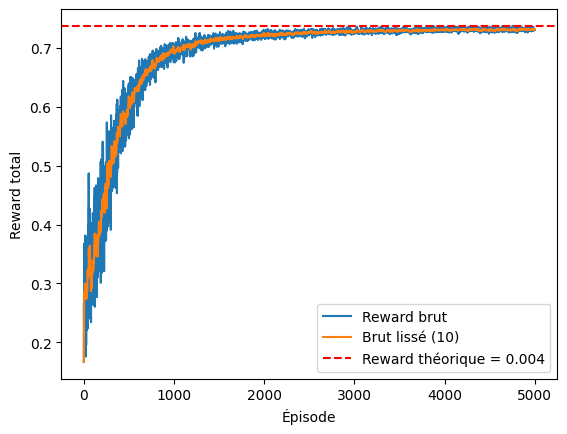

In [67]:
plt.plot(reward_history, label='Reward brut')
window = 10
smoothed = [np.mean(reward_history[max(0,i-window+1):(i+1)]) for i in range(len(reward_history))]
plt.plot(smoothed, label=f'Brut lissé ({window})')

# nouvelle ligne horizontale
plt.axhline(
    y=0.737, 
    color='r', 
    linestyle='--', 
    linewidth=1.5,
    label=f'Reward théorique = {reward:.3f}'
)

plt.xlabel("Épisode")
plt.ylabel("Reward total")
plt.legend()
plt.show()

In [68]:
depasse = False

for i in range(len(reward_history)):
    if reward_history[i] > 0.7370931146505718:
        print(reward_history[i])
        depasse = True
        
print(depasse)

0.7373821453017342
0.7371576510488028
0.7371859328177475
0.7374497026819674
True
